In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import joblib

In [2]:
import pandas as pd

df = pd.read_csv("spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [4]:
print(df.columns)

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')


In [5]:
df = df[['v1', 'v2']]

df.columns = ['label', 'message']

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [6]:
print(df.shape)

df.head()

(5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
print(df['label'].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [8]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df.head()

,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words='english')

X = vectorizer.fit_transform(df['message'])

y = df['label']

print(X.shape)

(5572, 8404)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (4457, 8404)
Testing : (1115, 8404)


In [11]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [12]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.968609865470852

Classification Report:

              precision    recall  f1-score   support

           0       0.96      1.00      0.98       965
           1       1.00      0.77      0.87       150

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.93      1115
weighted avg       0.97      0.97      0.97      1115



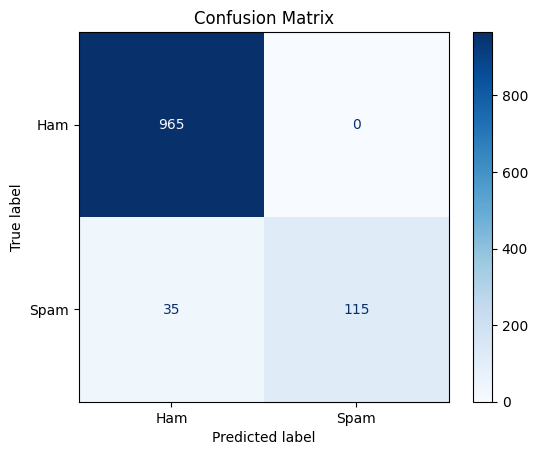

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

In [14]:
new_message = ["Congratulations! You have won a free iPhone. Click here to claim your prize now."]

new_vector = vectorizer.transform(new_message)

prediction = model.predict(new_vector)

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Ham")

Prediction: Spam


In [16]:
new_message = ["Hi Krishna, where are you? Let's meet at 5 PM."]

new_vector = vectorizer.transform(new_message)

prediction = model.predict(new_vector)

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Ham")

Prediction: Ham


In [17]:
message = ["Hi Krishna, are you coming to college today?"]

message_vector = vectorizer.transform(message)

prediction = model.predict(message_vector)

print("Message:", message[0])

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Ham")

Message: Hi Krishna, are you coming to college today?
Prediction: Ham


In [18]:
message = ["Your bank account has been blocked. Verify your account immediately by clicking this link."]

message_vector = vectorizer.transform(message)

prediction = model.predict(message_vector)

print("Message:", message[0])

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Ham")

Message: Your bank account has been blocked. Verify your account immediately by clicking this link.
Prediction: Ham


In [19]:
message = ["Your OTP is 482913. Do not share it with anyone."]

message_vector = vectorizer.transform(message)

prediction = model.predict(message_vector)

print("Message:", message[0])

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Ham")

Message: Your OTP is 482913. Do not share it with anyone.
Prediction: Ham


In [20]:
message = ["Tomorrow's Machine Learning class starts at 9:00 AM in Lab 2."]

message_vector = vectorizer.transform(message)

prediction = model.predict(message_vector)

print("Message:", message[0])

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Ham")

Message: Tomorrow's Machine Learning class starts at 9:00 AM in Lab 2.
Prediction: Ham


In [21]:
message = ["URGENT! Your mobile number has won a lottery worth ₹10,00,000. Call now to claim."]

message_vector = vectorizer.transform(message)
prediction = model.predict(message_vector)

print("Prediction:", "Spam" if prediction[0] == 1 else "Ham")

Prediction: Spam


In [22]:
message = ["Can you send me the notes after class?"]

message_vector = vectorizer.transform(message)
prediction = model.predict(message_vector)

print("Prediction:", "Spam" if prediction[0] == 1 else "Ham")

Prediction: Ham


In [23]:
message = ["Limited time offer! Buy one get one free. Visit our website today."]

message_vector = vectorizer.transform(message)
prediction = model.predict(message_vector)

print("Prediction:", "Spam" if prediction[0] == 1 else "Ham")

Prediction: Ham


In [24]:
message = ["Congratulations! You have been selected for a free vacation package. Reply YES to claim."]

message_vector = vectorizer.transform(message)
prediction = model.predict(message_vector)

print("Prediction:", "Spam" if prediction[0] == 1 else "Ham")

Prediction: Spam


In [25]:
message = ["can i call you later."]

message_vector = vectorizer.transform(message)
prediction = model.predict(message_vector)

print("Prediction:", "Spam" if prediction[0] == 1 else "Ham")

Prediction: Ham


In [26]:
import joblib

joblib.dump(model, "spam_sms_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [27]:
print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df["label"].value_counts())

Dataset Shape: (5572, 2)

Class Distribution:
label
0    4825
1     747
Name: count, dtype: int64
